# Global Solution – Classificação de ocorrências em São Paulo: Roubo × Furto com MLP

**Objetivo:** dadas as características de uma ocorrência, estimar se o registro é mais compatível com **roubo** ou **furto**. O modelo **não** prevê se um crime vai acontecer.

**Fonte dos dados:** SSP-SP, Portal de Estatísticas → Bases de Dados → *Celulares Subtraídos 2025* (https://www.ssp.sp.gov.br/estatistica/consultas). Para obter: baixar o arquivo `CelularesSubtraidos_2025` (CSV/XLSX) no portal e salvar como `CelularesSubtraidos_2025.csv`.

In [1]:
import pandas as pd
import numpy as np

CAMINHO = '/content/CelularesSubtraidos_2025.csv'   # ajuste se necessário
df = pd.read_csv(CAMINHO, sep=';', encoding='latin1', low_memory=False)
print(f"Total de registros originais: {len(df)}")
print(df.columns.tolist())

Total de registros originais: 383635
['ID_DELEGACIA', 'NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'CIRCUNSTANCIA', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'CIDADE', 'BAIRRO', 'CEP', 'LOGRADOURO_VERSAO', 'LOGRADOURO', 'NUMERO_LOGRADOURO', 'LATITUDE', 'LONGITUDE', 'CONT_OBJETO', 'DESCR_MODO_OBJETO', 'DESCR_TIPO_OBJETO', 'DESCR_SUBTIPO_OBJETO', 'DESCR_UNIDADE', 'QUANTIDADE_OBJETO', 'MARCA_OBJETO', 'FLAG_BLOQUEIO', 'FLAG_DESBLOQUEIO', 'MES_REGISTRO_BO', 'ANO_REGISTRO_BO', 'CMD', 'BTL', 'CIA', 'CD_IBGE']


## 1. Recorte, rótulo e atributos

- **Recorte geográfico:** `NOME_MUNICIPIO_CIRC` = São Paulo (município do **fato**, e não o da delegacia onde o BO foi registrado).
- **Duplicidades:** um BO pode ter vários itens (várias linhas); mantemos uma linha por BO (`NOME_DELEGACIA` + `ANO_BO` + `NUM_BO`).
- **Rótulo:** `RUBRICA` → 0 = Furto (art. 155), 1 = Roubo (art. 157). A rubrica **não** entra como entrada (evita *data leakage*).
- **Atributos escolhidos** (descrevem o local, o momento e o objeto da ocorrência): bairro, logradouro, período do dia, subtipo do local, marca do celular e dia da semana.
- **Atributos descartados de propósito:** `DESCR_CONDUTA`, `DESDOBRAMENTO` e `CIRCUNSTANCIA` (já descrevem a qualificação penal, quase revelam o rótulo) e campos do procedimento de registro (`DESCRICAO_APRESENTACAO`, `AUTORIA_BO`, flags), que dizem como o BO foi feito e não como a ocorrência aconteceu.
- **Período do dia:** `DESCR_PERIODO` só vem preenchido quando `HORA_OCORRENCIA` está vazia (nunca as duas juntas). Usar "NÃO INFORMADO" separava roubo (89%) de furto (25%) por um artefato do preenchimento e inflava a acurácia para ≈0,82 sem aprender nada sobre a ocorrência. Por isso o período é **derivado da hora** quando ela existe, e `DESCR_PERIODO` é usado só como reserva.
- **Categorias raras:** bairros, logradouros e subtipos pouco frequentes são agrupados em `OUTROS` (mantemos os 200 bairros, 300 logradouros e 60 subtipos mais frequentes), para limitar a dimensão do One-Hot.

In [2]:
from sklearn.model_selection import train_test_split

# Recorte geográfico + um registro por BO
df_sp = df[df['NOME_MUNICIPIO_CIRC'].astype(str).str.upper().isin(['S.PAULO', 'SÃO PAULO', 'SAO PAULO'])].copy()
df_sp = df_sp.drop_duplicates(subset=['NOME_DELEGACIA', 'ANO_BO', 'NUM_BO'])

# Rótulo (0 = Furto, 1 = Roubo)
d = df_sp[df_sp['RUBRICA'].isin(['Roubo (art. 157)', 'Furto (art. 155)'])].copy()
d['ALVO'] = d['RUBRICA'].map({'Furto (art. 155)': 0, 'Roubo (art. 157)': 1})

# Período unificado (hora → período; DESCR_PERIODO como reserva)
hora = pd.to_numeric(d['HORA_OCORRENCIA'].astype(str).str.extract(r'^(\d{1,2})')[0], errors='coerce')
periodo_hora = np.select([hora < 6, hora < 12, hora < 18], ['De madrugada', 'Pela manhã', 'A tarde'], default='A noite')
d['PERIODO'] = np.where(hora.notna(), periodo_hora, d['DESCR_PERIODO'])

# Dia da semana do fato
data = pd.to_datetime(d['DATA_OCORRENCIA_BO'], format='%d/%m/%Y', errors='coerce')
d['DIA_SEMANA'] = data.dt.dayofweek.map({0:'Segunda',1:'Terça',2:'Quarta',3:'Quinta',4:'Sexta',5:'Sábado',6:'Domingo'})

# Agrupa categorias raras em OUTROS
def top_n(serie, n):
    serie = serie.fillna('NÃO INFORMADO').astype(str)
    manter = set(serie.value_counts().index[:n])
    return serie.where(serie.isin(manter), 'OUTROS')

d['BAIRRO_T'] = top_n(d['BAIRRO'], 200)
d['LOGRADOURO_T'] = top_n(d['LOGRADOURO'], 300)
d['SUBLOCAL_T'] = top_n(d['DESCR_SUBTIPOLOCAL'], 60)
d['MARCA_T'] = top_n(d['MARCA_OBJETO'], 20)
d['PERIODO'] = d['PERIODO'].fillna('NÃO INFORMADO').astype(str)
d['DIA_SEMANA'] = d['DIA_SEMANA'].fillna('NÃO INFORMADO').astype(str)

ATRIBUTOS = ['BAIRRO_T', 'LOGRADOURO_T', 'PERIODO', 'SUBLOCAL_T', 'MARCA_T', 'DIA_SEMANA']

# Balanceamento: usa TODOS os roubos e o mesmo número de furtos sorteados
n_classe = d['ALVO'].value_counts().min()
df_final = pd.concat([d[d['ALVO'] == 1].sample(n_classe, random_state=42),
                      d[d['ALVO'] == 0].sample(n_classe, random_state=42)]).sample(frac=1, random_state=42).reset_index(drop=True)

# One-Hot (entradas 0/1: não precisam de escalonamento)
X = pd.get_dummies(df_final[ATRIBUTOS]).astype(np.float32)
y = df_final['ALVO'].values

# Treino 64% | Validação 16% | Teste 20% (estratificado)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.20, random_state=42, stratify=y_temp)

print(f"Registros em SP (fato, sem BO duplicado): {len(df_sp)} | Roubo/Furto: {len(d)}")
print(f"Base balanceada: {len(df_final)} ({n_classe} por classe) | Colunas de entrada: {X.shape[1]}")
print(f"Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}")
print(df_final.groupby('PERIODO')['ALVO'].agg(['mean', 'count']))

Registros em SP (fato, sem BO duplicado): 185088 | Roubo/Furto: 160024
Base balanceada: 117176 (58588 por classe) | Colunas de entrada: 595
Treino: 74992 | Validação: 18748 | Teste: 23436
                     mean  count
PERIODO                         
A noite          0.578781  44789
A tarde          0.400439  29153
De madrugada     0.603156  18123
Em hora incerta  0.325879    313
Pela manhã       0.401565  24798


## 2. Arquiteturas da MLP

Todas: entrada com uma coluna por categoria (One-Hot), camadas ocultas **ReLU** (simples e evita gradientes que desaparecem), saída com **1 neurônio sigmoid** (probabilidade de roubo), perda **binary_crossentropy** e otimizador **Adam** (lr = 0,001). Treino com `EarlyStopping` (monitora `val_loss`, paciência 4, restaura os melhores pesos), igual para todas.

| Modelo | Camadas ocultas | O que muda |
|---|---|---|
| Arq. 1 (Base) | 64 → 32 | referência |
| Arq. 2 (Dropout) | 64 → 32 + Dropout 0,3 | regularização |
| Arq. 3 (Profunda) | 128 → 64 → 32 + Dropout 0,3 | mais capacidade |
| Arq. 4 (Larga) | 256 → 128 + Dropout 0,5 | mais neurônios, regularização forte |

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

n_entrada = X_train.shape[1]

def criar_modelo(nome):
    tf.keras.utils.set_random_seed(42)
    ocultas = {
        'Arq. 1 (Base)':     [Dense(64, activation='relu'), Dense(32, activation='relu')],
        'Arq. 2 (Dropout)':  [Dense(64, activation='relu'), Dropout(0.3), Dense(32, activation='relu'), Dropout(0.3)],
        'Arq. 3 (Profunda)': [Dense(128, activation='relu'), Dropout(0.3), Dense(64, activation='relu'), Dropout(0.3), Dense(32, activation='relu')],
        'Arq. 4 (Larga)':    [Dense(256, activation='relu'), Dropout(0.5), Dense(128, activation='relu'), Dropout(0.5)],
    }[nome]
    m = Sequential([Input(shape=(n_entrada,))] + ocultas + [Dense(1, activation='sigmoid')])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    return m

modelos, historicos = {}, {}
for nome in ['Arq. 1 (Base)', 'Arq. 2 (Dropout)', 'Arq. 3 (Profunda)', 'Arq. 4 (Larga)']:
    modelos[nome] = criar_modelo(nome)
    parar = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
    print(f"--- Treinando {nome} ---")
    historicos[nome] = modelos[nome].fit(X_train, y_train, validation_data=(X_val, y_val),
                                         epochs=40, batch_size=128, callbacks=[parar], verbose=0)
    h = historicos[nome].history
    print(f"Épocas executadas: {len(h['loss'])} | melhor época (menor val_loss): {int(np.argmin(h['val_loss'])) + 1}")

--- Treinando Arq. 1 (Base) ---
Épocas executadas: 7 | melhor época (menor val_loss): 3
--- Treinando Arq. 2 (Dropout) ---
Épocas executadas: 9 | melhor época (menor val_loss): 5
--- Treinando Arq. 3 (Profunda) ---
Épocas executadas: 6 | melhor época (menor val_loss): 2
--- Treinando Arq. 4 (Larga) ---
Épocas executadas: 8 | melhor época (menor val_loss): 4


## 3. Comparação na validação e escolha do modelo

A escolha é feita **só com a validação** (maior F1). O conjunto de teste é usado uma única vez, na avaliação final.

In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def metricas(modelo, X_, y_):
    pred = (modelo.predict(X_, verbose=0) > 0.5).astype(int).ravel()
    return [accuracy_score(y_, pred), precision_score(y_, pred), recall_score(y_, pred), f1_score(y_, pred)]

df_comparativo = pd.DataFrame({n: metricas(m, X_val, y_val) for n, m in modelos.items()},
                              index=['Acurácia', 'Precision', 'Recall', 'F1-Score']).T
print("--- TABELA COMPARATIVA (VALIDAÇÃO) ---")
print(df_comparativo.round(4))

nome_escolhido = df_comparativo['F1-Score'].idxmax()
modelo_escolhido = modelos[nome_escolhido]
historico_escolhido = historicos[nome_escolhido]
print(f"\nModelo escolhido (maior F1 na validação): {nome_escolhido}")

--- TABELA COMPARATIVA (VALIDAÇÃO) ---
                   Acurácia  Precision  Recall  F1-Score
Arq. 1 (Base)        0.7163     0.7091  0.7336    0.7212
Arq. 2 (Dropout)     0.7160     0.7106  0.7289    0.7196
Arq. 3 (Profunda)    0.7153     0.7087  0.7311    0.7197
Arq. 4 (Larga)       0.7169     0.7067  0.7417    0.7238

Modelo escolhido (maior F1 na validação): Arq. 4 (Larga)


## 4. Avaliação final (teste), curvas e matriz de confusão

--- RELATÓRIO FINAL NO TESTE: Arq. 4 (Larga) ---
              precision    recall  f1-score   support

   Furto (0)       0.72      0.69      0.71     11718
   Roubo (1)       0.70      0.73      0.72     11718

    accuracy                           0.71     23436
   macro avg       0.71      0.71      0.71     23436
weighted avg       0.71      0.71      0.71     23436



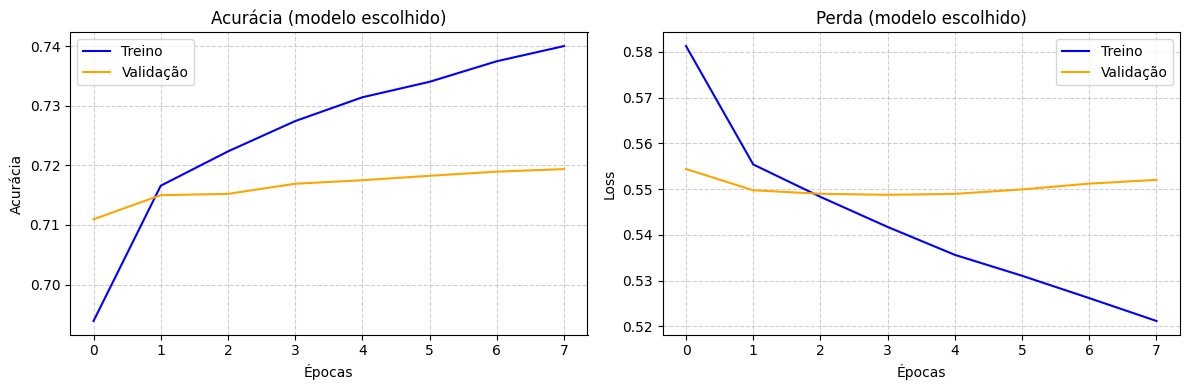

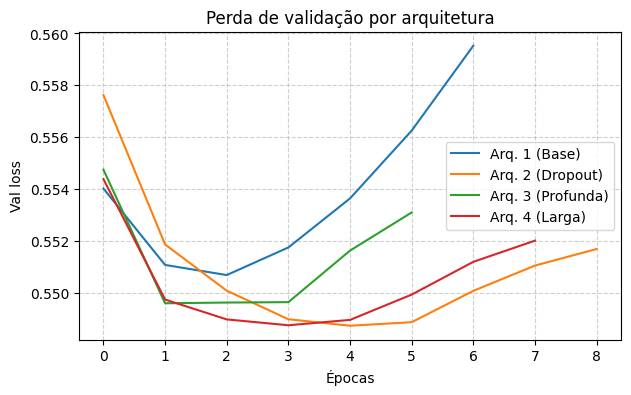

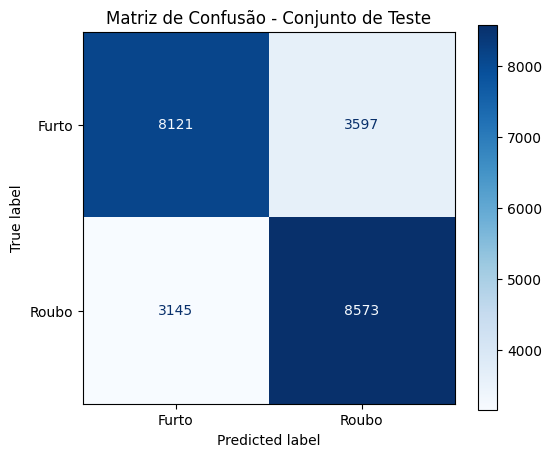

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = (modelo_escolhido.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
print(f"--- RELATÓRIO FINAL NO TESTE: {nome_escolhido} ---")
print(classification_report(y_test, y_pred, target_names=['Furto (0)', 'Roubo (1)']))

h = historico_escolhido.history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(h['accuracy'], label='Treino', color='blue'); ax1.plot(h['val_accuracy'], label='Validação', color='orange')
ax1.set_title('Acurácia (modelo escolhido)'); ax1.set_xlabel('Épocas'); ax1.set_ylabel('Acurácia'); ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.6)
ax2.plot(h['loss'], label='Treino', color='blue'); ax2.plot(h['val_loss'], label='Validação', color='orange')
ax2.set_title('Perda (modelo escolhido)'); ax2.set_xlabel('Épocas'); ax2.set_ylabel('Loss'); ax2.legend(); ax2.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
for nome, hist in historicos.items():
    plt.plot(hist.history['val_loss'], label=nome)
plt.title('Perda de validação por arquitetura'); plt.xlabel('Épocas'); plt.ylabel('Val loss'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.6); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Furto', 'Roubo']).plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Matriz de Confusão - Conjunto de Teste'); plt.show()

## 5. Salvando o modelo e as categorias para a aplicação web

Salvamos o modelo, a lista exata de colunas do treino e as categorias válidas de cada atributo (usadas nos campos de seleção do app).

In [6]:
import pickle

modelo_escolhido.save('modelo_mlp.h5')
with open('colunas_treino.pkl', 'wb') as f:
    pickle.dump(list(X.columns), f)

ordem_dia = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
categorias_dropdown = {c: sorted(df_final[c].unique()) for c in ATRIBUTOS}
categorias_dropdown['DIA_SEMANA'] = [x for x in ordem_dia if x in set(df_final['DIA_SEMANA'])]
with open('categorias_dropdown.pkl', 'wb') as f:
    pickle.dump(categorias_dropdown, f)

print(f"Modelo '{nome_escolhido}' salvo. Colunas de entrada: {len(X.columns)}")

Modelo 'Arq. 4 (Larga)' salvo. Colunas de entrada: 595
